In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%pip install openpyxl


Note: you may need to restart the kernel to use updated packages.


- Importing Excel file with data for plotting. 

In [20]:
file = "Boise_SNOTEL_TwinSprings_exceedance.final.xlsx"
sheets = pd.read_excel(file, sheet_name=None)

print(sheets.keys()) 

for name, data in sheets.items():
    print(name, data.shape)

dict_keys(['WY2026 comparison', 'Total P', 'Apr 1 SWE', 'Max SWE', 'Cum P thru Apr 1', 'Apr 1 SWE-P ratio', 'Snow fraction', 'Total P curve', 'Apr 1 SWE curve', 'Max SWE curve', 'Cum P thru Apr 1 curve', 'Notes', 'Twin Springs daily', 'Twin Springs', 'Twin Springs 1981-2026', 'Twin Springs curve'])
WY2026 comparison (37, 9)
Total P (46, 11)
Apr 1 SWE (46, 11)
Max SWE (46, 11)
Cum P thru Apr 1 (46, 11)
Apr 1 SWE-P ratio (46, 11)
Snow fraction (46, 11)
Total P curve (46, 11)
Apr 1 SWE curve (46, 11)
Max SWE curve (46, 11)
Cum P thru Apr 1 curve (46, 11)
Notes (26, 2)
Twin Springs daily (42187, 7)
Twin Springs (116, 19)
Twin Springs 1981-2026 (46, 13)
Twin Springs curve (116, 9)


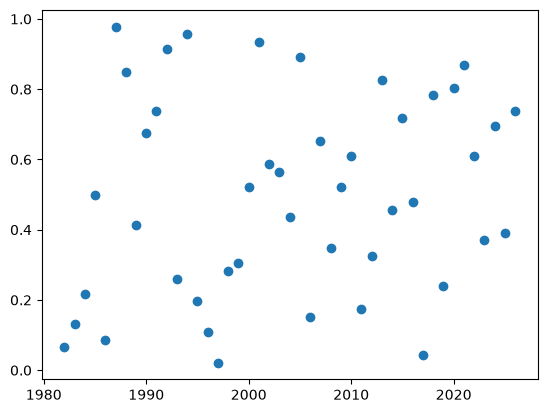

In [ ]:
# basic scatter plot of water year at mores creek. 

total_p = sheets["Total P"]

plt.scatter(total_p['Water Year'], total_p['Mores Creek Summit Exceed. P'])
plt.show()

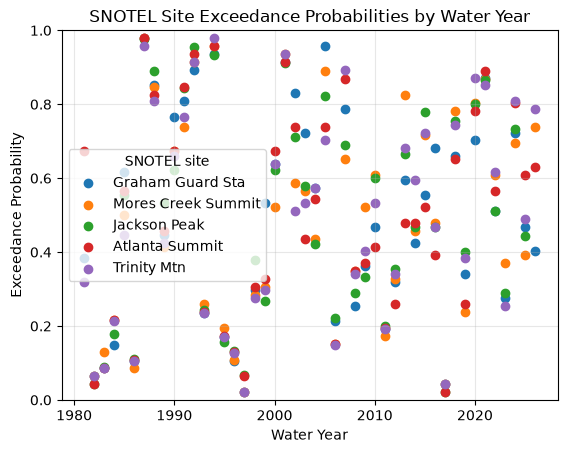

In [ ]:
#Exceedance value graph showing yearly for each site. 

site_cols = [col for col in total_p.columns if col.endswith("Exceed. P")]

for col in site_cols:
    site_data = total_p.dropna(subset=["Water Year", col])
    plt.scatter(
        site_data["Water Year"],
        site_data[col],
        label=col.replace(" Exceed. P", "")
    )

plt.xlabel("Water Year")
plt.ylabel("Exceedance Probability")
plt.title("SNOTEL Site Exceedance Probabilities by Water Year")
plt.ylim(0, 1)
plt.legend(title="SNOTEL site")
plt.grid(True, alpha=0.3)
plt.show()

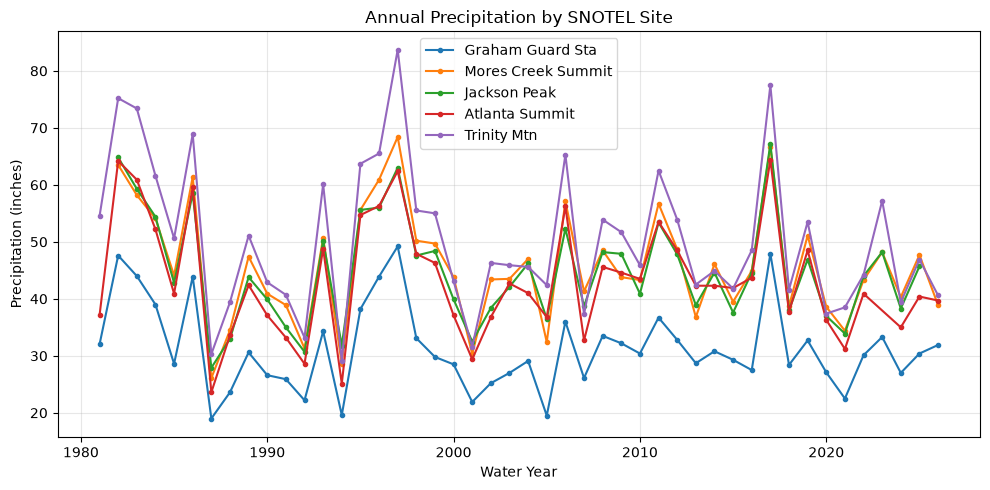

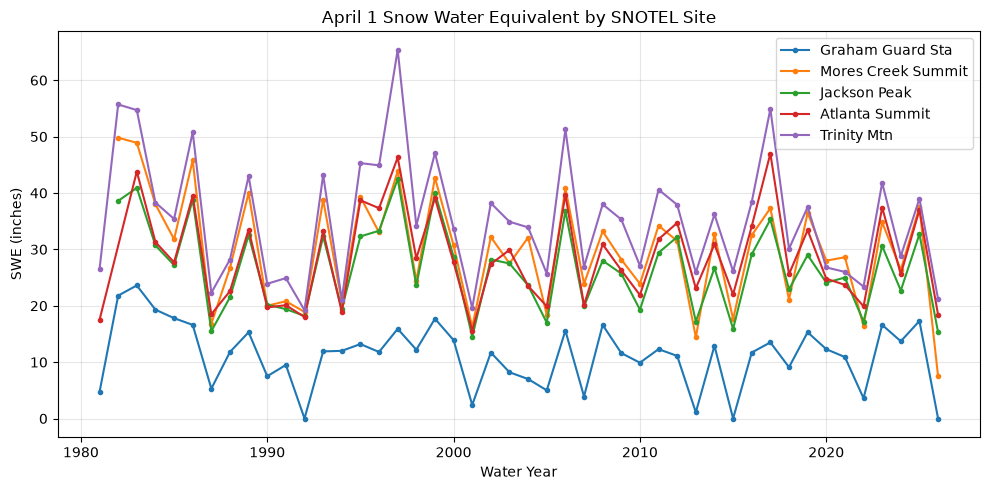

In [29]:
#Annual precip an april 1 swe by water year
sites = [
    "Graham Guard Sta",
    "Mores Creek Summit",
    "Jackson Peak",
    "Atlanta Summit",
    "Trinity Mtn",
]

for sheet_name, title, ylabel in [
    ("Total P", "Annual Precipitation", "Precipitation (inches)"),
    ("Apr 1 SWE", "April 1 Snow Water Equivalent", "SWE (inches)"),
]:
    data = sheets[sheet_name]

    fig, ax = plt.subplots(figsize=(10, 5))

    for site in sites:
        column = f"{site} (in)"
        plot_data = data.dropna(subset=["Water Year", column])
        ax.plot(
            plot_data["Water Year"],
            plot_data[column],
            marker="o",
            markersize=3,
            label=site,
        )

    ax.set(
        xlabel="Water Year",
        ylabel=ylabel,
        title=f"{title} by SNOTEL Site",
    )
    ax.legend()
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    plt.show()


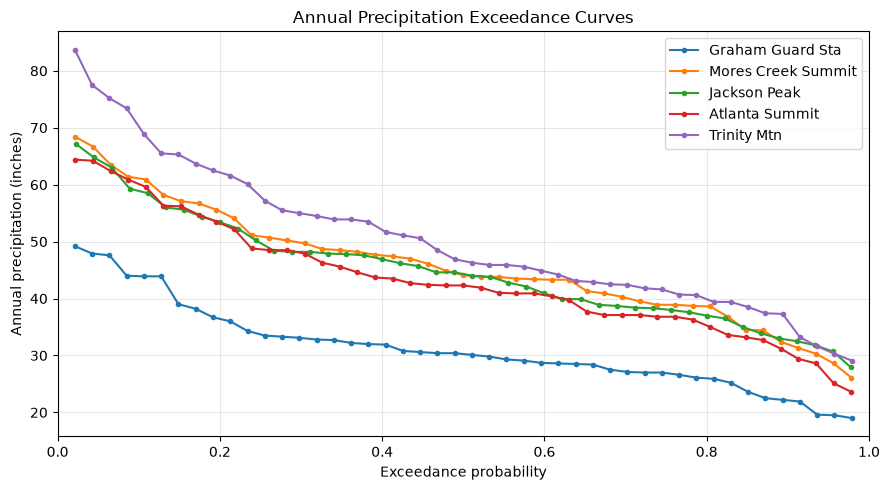

In [ ]:
#Exceedance curves for annual precip
curve = sheets["Total P curve"]

fig, ax = plt.subplots(figsize=(9, 5))

for site in sites:
    probability_col = f"{site} Exceed. P"
    precipitation_col = f"{site} (in)"

    ax.plot(
        curve[probability_col],
        curve[precipitation_col],
        marker=".",
        label=site,
    )

ax.set(
    xlabel="Exceedance probability",
    ylabel="Annual precipitation (inches)",
    title="Annual Precipitation Exceedance Curves",
    xlim=(0, 1),
)
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

#I feel like this plot isnt very helpful since it just shows that lower precip has higher exceedance values

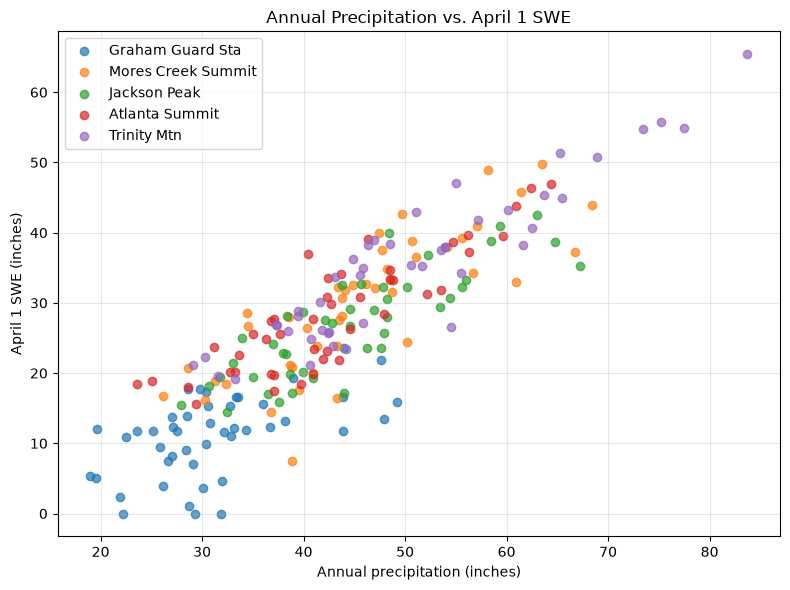

In [ ]:
#Precip vs april 1 swe

precip = sheets["Total P"]
swe = sheets["Apr 1 SWE"]

fig, ax = plt.subplots(figsize=(8, 6))

for site in sites:
    precip_col = f"{site} (in)"

    precip_site = precip[["Water Year", precip_col]].rename(
        columns={precip_col: "Precipitation"}
    )
    swe_site = swe[["Water Year", precip_col]].rename(
        columns={precip_col: "SWE"}
    )

    site_data = precip_site.merge(swe_site, on="Water Year").dropna()

    ax.scatter(
        site_data["Precipitation"],
        site_data["SWE"],
        label=site,
        alpha=0.7,
    )

ax.set(
    xlabel="Annual precipitation (inches)",
    ylabel="April 1 SWE (inches)",
    title="Annual Precipitation vs. April 1 SWE",
)
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

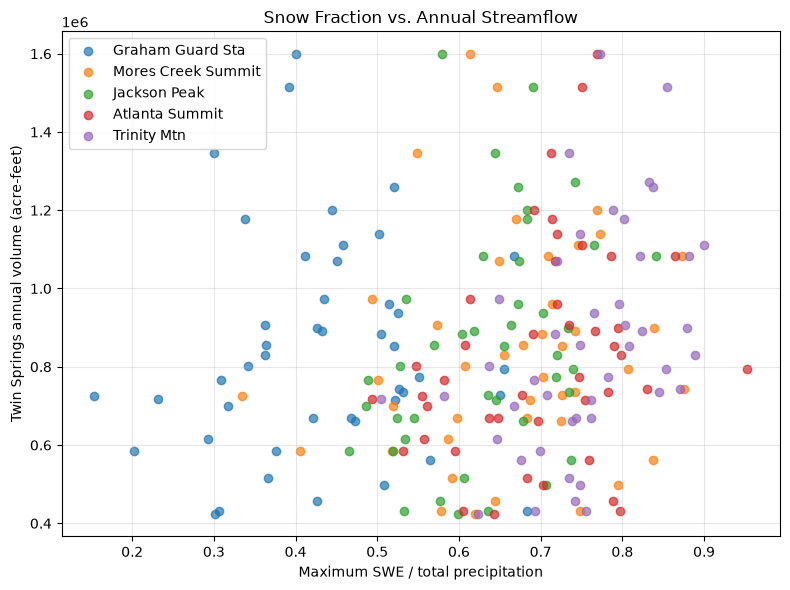

In [33]:
#Snow fraction vs annual streamflow
snow = sheets["Snow fraction"]
flow = sheets["Twin Springs 1981-2026"]

flow_col = "Annual volume (acre-ft)"
flow_by_year = flow[["Water Year", flow_col]].copy()
flow_by_year["Water Year"] = pd.to_numeric(
    flow_by_year["Water Year"], errors="coerce"
)

fig, ax = plt.subplots(figsize=(8, 6))

for site in sites:
    fraction_col = f"{site} Max SWE / Total P"
    site_data = snow[["Water Year", fraction_col]].copy()
    site_data["Water Year"] = pd.to_numeric(
        site_data["Water Year"], errors="coerce"
    )

    matched = site_data.merge(flow_by_year, on="Water Year").dropna()

    ax.scatter(
        matched[fraction_col],
        matched[flow_col],
        label=site,
        alpha=0.7,
    )

ax.set(
    xlabel="Maximum SWE / total precipitation",
    ylabel="Twin Springs annual volume (acre-feet)",
    title="Snow Fraction vs. Annual Streamflow",
)
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

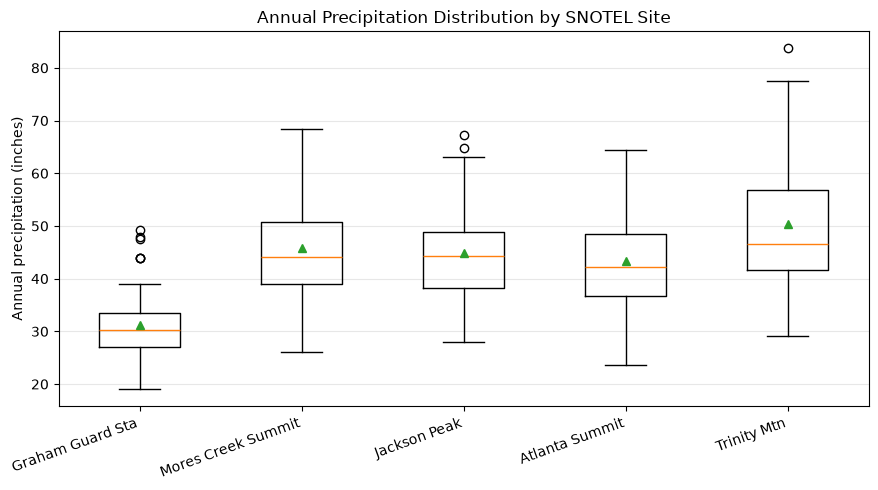

In [35]:
#Comparing annprecip = sheets["Total P"]

values = [
    pd.to_numeric(precip[f"{site} (in)"], errors="coerce").dropna()
    for site in sites
]

fig, ax = plt.subplots(figsize=(9, 5))
ax.boxplot(values, showmeans=True)
ax.set_xticks(range(1, len(sites) + 1), sites, rotation=20, ha="right")
ax.set(
    ylabel="Annual precipitation (inches)",
    title="Annual Precipitation Distribution by SNOTEL Site",
)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()


### Correlation plots 


Matched annual observations using the 'Apr 1 SWE' sheet:
 Water Year  Graham Guard Sta (in)  Graham Guard Sta Exceed. P  Mores Creek Summit (in)  Mores Creek Summit Exceed. P  Jackson Peak (in)  Jackson Peak Exceed. P  Atlanta Summit (in)  Atlanta Summit Exceed. P  Trinity Mtn (in)  Trinity Mtn Exceed. P  annual_total_acre_ft  observed_hours
       1986                   16.6                    0.148936                     45.8                      0.065217               38.8                0.086957                 39.5                  0.108696              50.8               0.127660          5.823807e+04         1624.00
       1987                    5.3                    0.787234                     16.8                      0.891304               15.5                0.934783                 18.5                  0.891304              22.3               0.893617          4.081874e+05         8004.00
       1988                   11.8                    0.510638                    

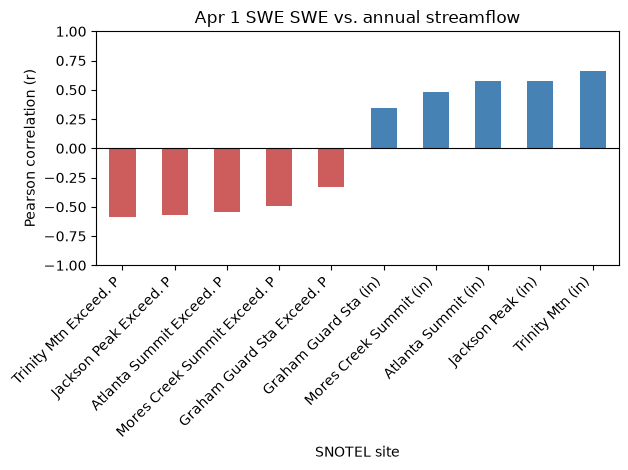

In [2]:
#1 
%run ./swe_streamflow_correlation.py